In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Environment ready!")

Environment ready!


# Week 2 - Baseline Models and Evaluation

**Project:** Predicting Term Deposit Subscription

**Author:** Mariem Dridi

## 1. Objective

The objective of this notebook is to implement and evaluate
two baseline models: a Dummy Classifier and Logistic Regression.

We reuse the cleaned dataset and preprocessing functions
developed in the previous module.

All models are fitted on the training set and evaluated on
the validation set. The test set is reserved for final evaluation.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_curve
)

from src.data_prep import split, build_preprocessor

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Data Loading

We use the cleaned dataset containing 41,176 observations.

The cleaning process has already removed exact duplicates,
excluded the duration feature to prevent data leakage,
and encoded the target variable as 0 and 1.

No additional cleaning is performed in this notebook.

In [3]:
df = pd.read_csv("bank_clean.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

df.head()

Dataset shape: (41176, 21)

Column names:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y', 'was_contacted_before']


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,was_contacted_before
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,0,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,0,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,0,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,0,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,0,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0


In [4]:
assert len(df) == 41176, "Unexpected number of rows"
assert df.shape[1] == 21, "Unexpected number of columns"
assert "duration" not in df.columns, "Data leakage detected"
assert set(df["y"].unique()) == {0, 1}, "Invalid target encoding"
assert df.isna().sum().sum() == 0, "Missing values detected"

print("All data checks passed.")

print("\nTarget distribution:")
print(df["y"].value_counts())

print("\nTarget distribution (%):")
print(df["y"].value_counts(normalize=True) * 100)

All data checks passed.

Target distribution:
y
0    36537
1     4639
Name: count, dtype: int64

Target distribution (%):
y
0    88.733728
1    11.266272
Name: proportion, dtype: float64


The dataset is highly imbalanced, with 88.73% of observations
belonging to the negative class and only 11.27% to the positive
class.

A model that always predicts no subscription could achieve
approximately 88.73% accuracy without identifying any actual
subscribers. Therefore, accuracy alone is not sufficient to
evaluate model performance.

We will focus on Average Precision, recall, precision,
F1-score and ROC-AUC.

## 3. Train, Validation and Test Split

We reuse the stratified splitting function from the
preprocessing module with random_state=42.

- Training set (60%): model fitting.
- Validation set (20%): model evaluation and threshold selection.
- Test set (20%): final evaluation only.

Stratification preserves the target class proportions
across the three subsets.

In [5]:
X_train, X_val, X_test, y_train, y_val, y_test = split(df)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

assert len(X_train) == 24705
assert len(X_val) == 8235
assert len(X_test) == 8236

assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

print("\nSplit checks passed.")

Training set: (24705, 20)
Validation set: (8235, 20)
Test set: (8236, 20)

Split checks passed.


In [6]:
split_summary = pd.DataFrame({
    "Training": y_train.value_counts(normalize=True) * 100,
    "Validation": y_val.value_counts(normalize=True) * 100
})

split_summary.round(2)

,Training,Validation
y,,
0,88.74,88.73
1,11.26,11.27


## 4. Dummy Classifier

The Dummy Classifier is used as a reference baseline.

With strategy="prior", it always predicts the majority class
and returns probabilities based on the training class distribution.

This baseline illustrates why accuracy alone is misleading
when dealing with imbalanced classification problems.

In [7]:
dummy_pipeline = Pipeline([
    ("preprocessor", build_preprocessor()),
    ("classifier", DummyClassifier(strategy="prior"))
])

dummy_pipeline.fit(X_train, y_train)

print("Dummy Classifier trained successfully.")

Dummy Classifier trained successfully.


In [8]:
dummy_pred = dummy_pipeline.predict(X_val)

dummy_proba = dummy_pipeline.predict_proba(X_val)[:, 1]

print("Predicted class distribution:")
print(pd.Series(dummy_pred).value_counts())

print("\nFirst 5 predicted probabilities:")
print(dummy_proba[:5])

Predicted class distribution:
0    8235
Name: count, dtype: int64

First 5 predicted probabilities:
[0.11264926 0.11264926 0.11264926 0.11264926 0.11264926]


In [9]:
dummy_results = {
    "Accuracy": accuracy_score(y_val, dummy_pred),
    "Precision": precision_score(y_val, dummy_pred, zero_division=0),
    "Recall": recall_score(y_val, dummy_pred, zero_division=0),
    "F1-score": f1_score(y_val, dummy_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val, dummy_proba),
    "Average Precision": average_precision_score(y_val, dummy_proba)
}

pd.DataFrame([dummy_results], index=["Dummy Classifier"]).round(4)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
Dummy Classifier,0.8873,0.0,0.0,0.0,0.5,0.1127


## 5. Logistic Regression

Logistic Regression is selected as our main baseline
because it is simple, interpretable and computationally
efficient for binary classification.

The model estimates the probability of a customer
subscribing to a term deposit.

We use the default regularization settings without
class weighting or resampling to establish a standard
baseline for future experiments.

The preprocessing and classification steps are combined
in a single pipeline fitted exclusively on the training set.

In [10]:
lr_pipeline = Pipeline([
    ("preprocessor", build_preprocessor()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

lr_pipeline.fit(X_train, y_train)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [11]:
lr_pred = lr_pipeline.predict(X_val)

lr_proba = lr_pipeline.predict_proba(X_val)[:, 1]

print("Predicted class distribution:")
print(pd.Series(lr_pred).value_counts())

print("\nFirst 5 predicted probabilities:")
print(lr_proba[:5])

Predicted class distribution:
0    7939
1     296
Name: count, dtype: int64

First 5 predicted probabilities:
[0.03707723 0.05124307 0.05016525 0.03620515 0.02008626]


In [12]:
lr_results = {
    "Accuracy": accuracy_score(y_val, lr_pred),
    "Precision": precision_score(y_val, lr_pred, zero_division=0),
    "Recall": recall_score(y_val, lr_pred, zero_division=0),
    "F1-score": f1_score(y_val, lr_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val, lr_proba),
    "Average Precision": average_precision_score(y_val, lr_proba)
}

pd.DataFrame(
    [lr_results],
    index=["Logistic Regression"]
).round(4)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
Logistic Regression,0.9012,0.6926,0.2209,0.335,0.8081,0.4742


## 6. Baseline Model Comparison

We compare the Dummy Classifier and Logistic Regression
on the same validation set using six evaluation metrics.

Due to class imbalance, we pay particular attention to
Average Precision, recall, F1-score and ROC-AUC.

In [13]:
comparison = pd.DataFrame(
    [dummy_results, lr_results],
    index=["Dummy Classifier", "Logistic Regression"]
)

comparison.round(4)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
Dummy Classifier,0.8873,0.0000,0.0000,0.000,0.5000,0.1127
Logistic Regression,0.9012,0.6926,0.2209,0.335,0.8081,0.4742


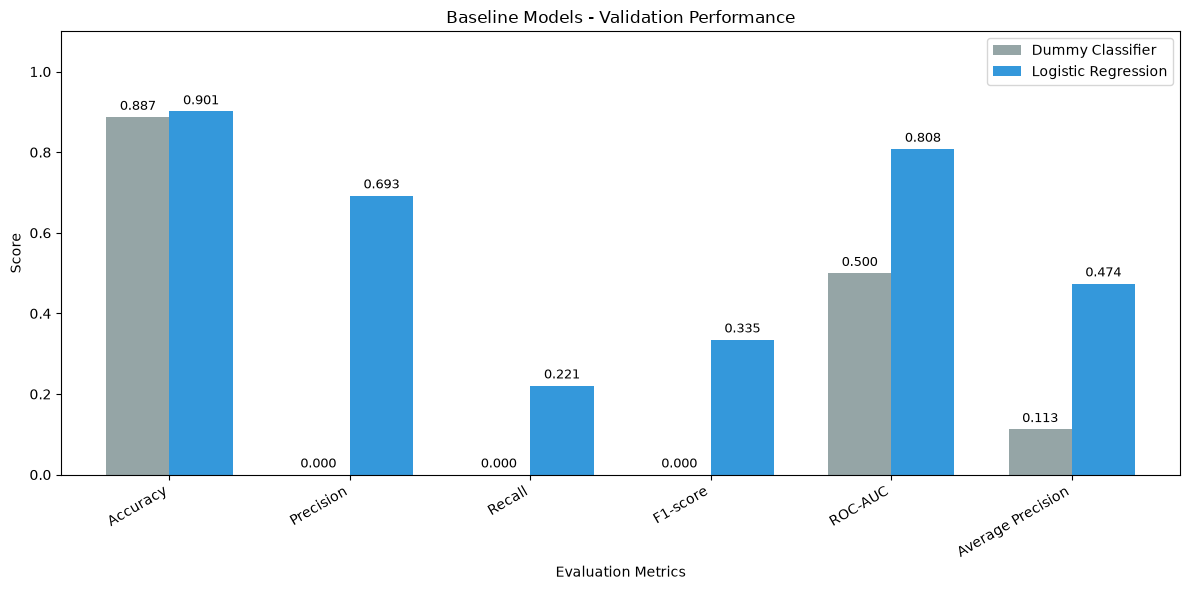

In [14]:
ax = comparison.T.plot(
    kind="bar",
    figsize=(12, 6),
    color=["#95A5A6", "#3498DB"],
    width=0.7
)

plt.title("Baseline Models - Validation Performance")
plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")
plt.ylim(0, 1.1)
plt.xticks(rotation=30, ha="right")
plt.legend(loc="upper right")

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=9)

plt.tight_layout()
plt.show()

### Model Comparison and Interpretation

Logistic Regression outperforms the Dummy Classifier
across all evaluation metrics.

The ROC-AUC of 0.8081 indicates good discrimination
ability, while Average Precision increases from
0.1127 to 0.4742.

However, despite a precision of 69.26%, the model
achieves a recall of only 22.09%, missing approximately
78% of actual subscribers.

This limitation is particularly important in bank
marketing, where missing potential subscribers may
represent lost business opportunities.

Threshold optimization will be explored to improve
the balance between precision and recall.

## 7. Confusion Matrices

Confusion matrices provide a detailed analysis of
correct and incorrect predictions for both models.

They help identify false positives and false negatives,
which are particularly important in bank marketing.

In [15]:
dummy_cm = confusion_matrix(y_val, dummy_pred)
lr_cm = confusion_matrix(y_val, lr_pred)

print("Dummy Classifier:")
print(dummy_cm)

print("\nLogistic Regression:")
print(lr_cm)

Dummy Classifier:
[[7307    0]
 [ 928    0]]

Logistic Regression:
[[7216   91]
 [ 723  205]]


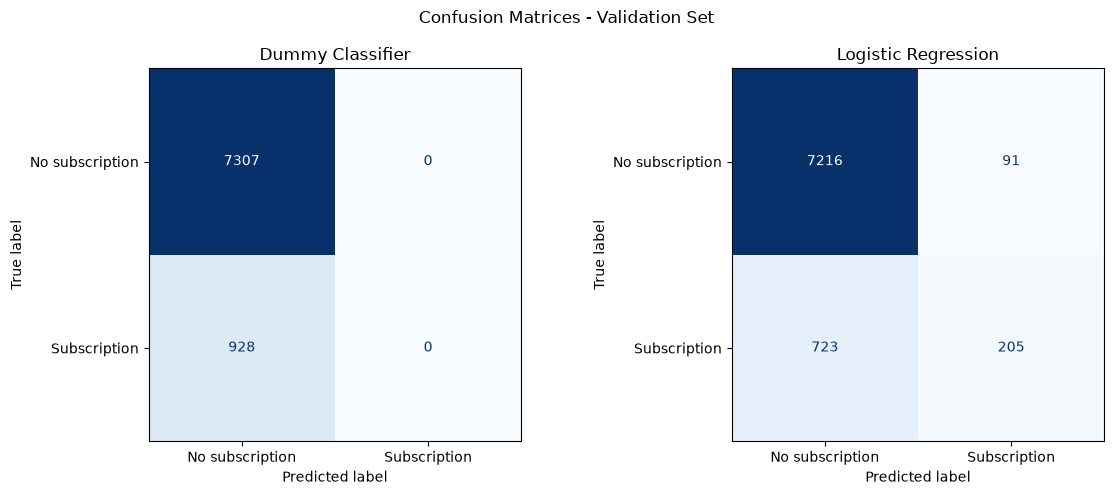

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix=dummy_cm,
    display_labels=["No subscription", "Subscription"]
).plot(ax=axes[0], cmap="Blues", colorbar=False)

axes[0].set_title("Dummy Classifier")

ConfusionMatrixDisplay(
    confusion_matrix=lr_cm,
    display_labels=["No subscription", "Subscription"]
).plot(ax=axes[1], cmap="Blues", colorbar=False)

axes[1].set_title("Logistic Regression")

plt.suptitle("Confusion Matrices - Validation Set")
plt.tight_layout()
plt.show()

## 8. ROC and Precision-Recall Curves

The ROC curve evaluates the model's ability to distinguish
between subscribers and non-subscribers across different
decision thresholds.

The Precision-Recall curve evaluates the trade-off between
precision and recall.

The Precision-Recall curve is particularly relevant
for our dataset because the positive class is underrepresented.

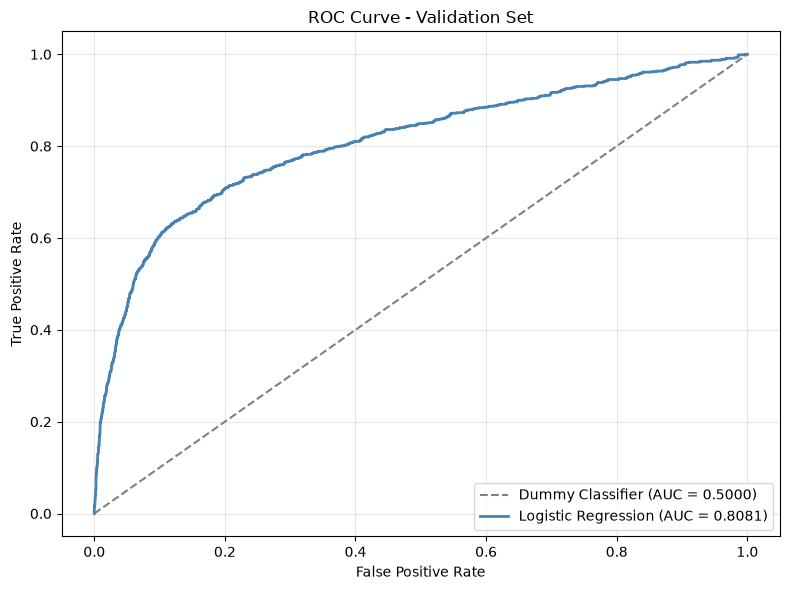

In [17]:
dummy_fpr, dummy_tpr, _ = roc_curve(y_val, dummy_proba)
lr_fpr, lr_tpr, _ = roc_curve(y_val, lr_proba)

plt.figure(figsize=(8, 6))

plt.plot(
    dummy_fpr, dummy_tpr,
    linestyle="--",
    color="gray",
    label=f"Dummy Classifier (AUC = {dummy_results['ROC-AUC']:.4f})"
)

plt.plot(
    lr_fpr, lr_tpr,
    color="steelblue",
    linewidth=2,
    label=f"Logistic Regression (AUC = {lr_results['ROC-AUC']:.4f})"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Validation Set")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

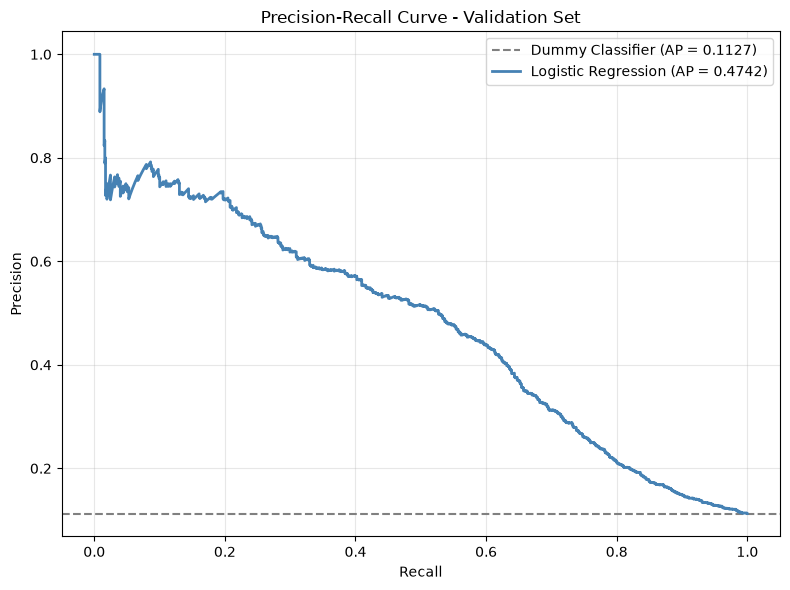

In [18]:
lr_precision, lr_recall, lr_thresholds = precision_recall_curve(
    y_val, lr_proba
)

baseline_ap = y_val.mean()

plt.figure(figsize=(8, 6))

plt.axhline(
    y=baseline_ap,
    color="gray",
    linestyle="--",
    label=f"Dummy Classifier (AP = {baseline_ap:.4f})"
)

plt.plot(
    lr_recall, lr_precision,
    color="steelblue",
    linewidth=2,
    label=f"Logistic Regression (AP = {lr_results['Average Precision']:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Validation Set")
plt.legend(loc="upper right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Decision Threshold Optimization

The default classification threshold of 0.5 results
in a low recall of 22.09%.

To improve the detection of potential subscribers,
we investigate alternative decision thresholds.

The optimal threshold is selected by maximizing the
F1-score on the validation set.

This approach balances precision and recall without
retraining the model.

The test set remains untouched to prevent data leakage
and preserve an independent final evaluation.

In [19]:
precision, recall, thresholds = precision_recall_curve(
    y_val, lr_proba
)

# Compute F1-score for each threshold
f1_scores = np.divide(
    2 * precision[:-1] * recall[:-1],
    precision[:-1] + recall[:-1],
    out=np.zeros_like(precision[:-1]),
    where=(precision[:-1] + recall[:-1]) != 0
)

# Find the threshold with the highest F1-score
best_idx = np.argmax(f1_scores)

best_threshold = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

print(f"Default threshold: 0.5000")
print(f"Optimal threshold: {best_threshold:.4f}")
print(f"Best F1-score: {best_f1:.4f}")
print(f"Precision: {precision[best_idx]:.4f}")
print(f"Recall: {recall[best_idx]:.4f}")

Default threshold: 0.5000
Optimal threshold: 0.2385
Best F1-score: 0.5156
Precision: 0.5046
Recall: 0.5269


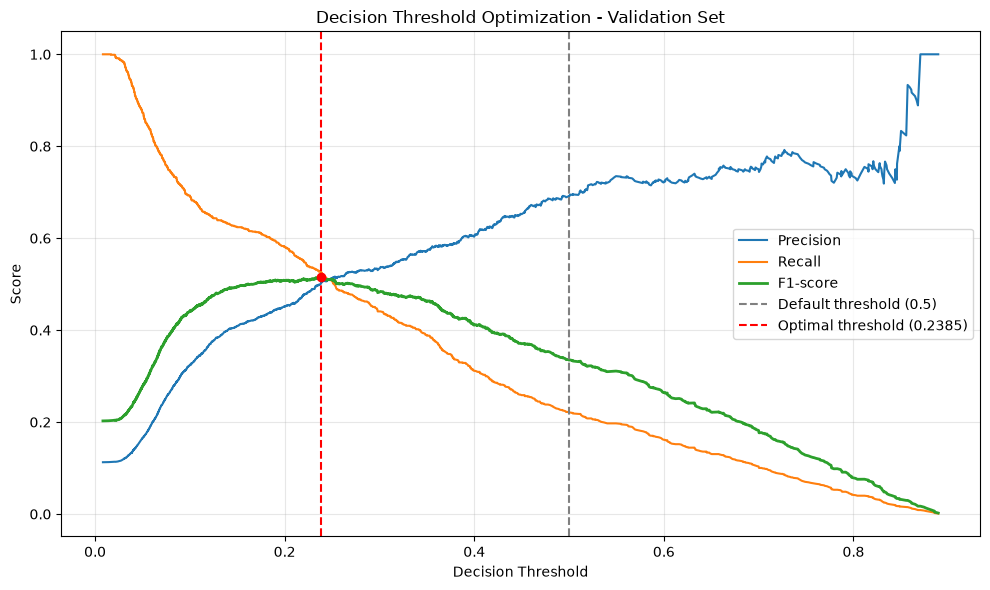

In [20]:
plt.figure(figsize=(10, 6))

plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")
plt.plot(thresholds, f1_scores, label="F1-score", linewidth=2)

plt.axvline(
    0.5,
    color="gray",
    linestyle="--",
    label="Default threshold (0.5)"
)

plt.axvline(
    best_threshold,
    color="red",
    linestyle="--",
    label=f"Optimal threshold ({best_threshold:.4f})"
)

plt.scatter(best_threshold, best_f1, color="red", zorder=5)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Decision Threshold Optimization - Validation Set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
lr_optimized_pred = (lr_proba >= best_threshold).astype(int)

lr_optimized_results = {
    "Accuracy": accuracy_score(y_val, lr_optimized_pred),
    "Precision": precision_score(
        y_val, lr_optimized_pred, zero_division=0
    ),
    "Recall": recall_score(y_val, lr_optimized_pred),
    "F1-score": f1_score(y_val, lr_optimized_pred),
    "ROC-AUC": roc_auc_score(y_val, lr_proba),
    "Average Precision": average_precision_score(y_val, lr_proba)
}

threshold_comparison = pd.DataFrame(
    [lr_results, lr_optimized_results],
    index=["Default Threshold", "Optimized Threshold"]
)

threshold_comparison.round(4)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
Default Threshold,0.9012,0.6926,0.2209,0.3350,0.8081,0.4742
Optimized Threshold,0.8884,0.5046,0.5269,0.5156,0.8081,0.4742


In [22]:
lr_optimized_cm = confusion_matrix(
    y_val, lr_optimized_pred
)

print("Default threshold (0.5):")
print(lr_cm)

print(f"\nOptimized threshold ({best_threshold:.4f}):")
print(lr_optimized_cm)

Default threshold (0.5):
[[7216   91]
 [ 723  205]]

Optimized threshold (0.2385):
[[6827  480]
 [ 439  489]]


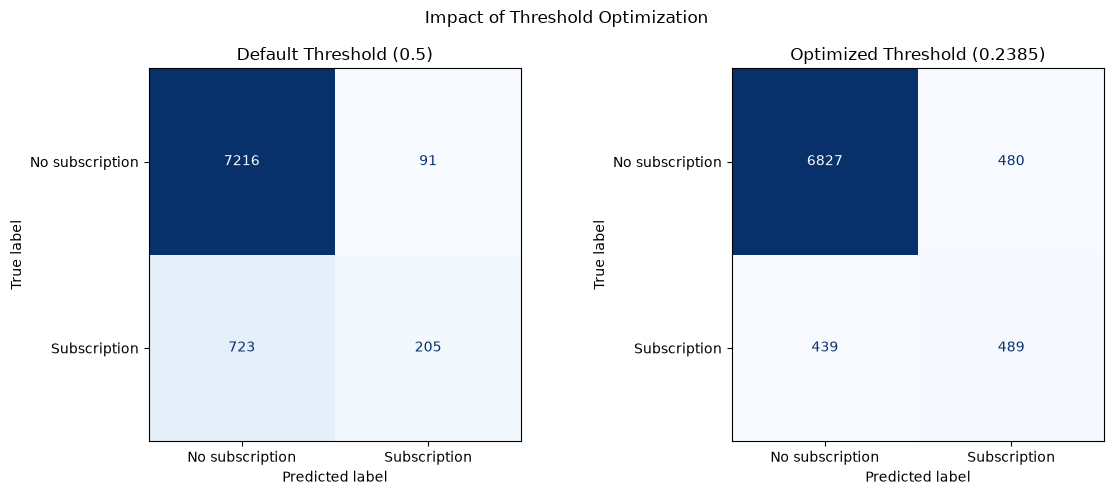

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix=lr_cm,
    display_labels=["No subscription", "Subscription"]
).plot(ax=axes[0], cmap="Blues", colorbar=False)

axes[0].set_title("Default Threshold (0.5)")

ConfusionMatrixDisplay(
    confusion_matrix=lr_optimized_cm,
    display_labels=["No subscription", "Subscription"]
).plot(ax=axes[1], cmap="Blues", colorbar=False)

axes[1].set_title(
    f"Optimized Threshold ({best_threshold:.4f})"
)

plt.suptitle("Impact of Threshold Optimization")
plt.tight_layout()
plt.show()

## 10. Final Baseline Performance Summary

In [24]:
final_comparison = pd.DataFrame(
    [
        dummy_results,
        lr_results,
        lr_optimized_results
    ],
    index=[
        "Dummy Classifier",
        "Logistic Regression (Default)",
        "Logistic Regression (Optimized)"
    ]
)

final_comparison.round(4)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
Dummy Classifier,0.8873,0.0000,0.0000,0.0000,0.5000,0.1127
Logistic Regression (Default),0.9012,0.6926,0.2209,0.3350,0.8081,0.4742
Logistic Regression (Optimized),0.8884,0.5046,0.5269,0.5156,0.8081,0.4742


## 11. Conclusion

### Main Findings

The Dummy Classifier demonstrates that accuracy alone
is misleading for our imbalanced dataset.

Logistic Regression provides a stronger baseline,
achieving a ROC-AUC of 0.8081 and an Average Precision
of 0.4742.

Optimizing the decision threshold to 0.2385 improves
recall from 22.09% to 52.69% and F1-score from 0.3350
to 0.5156.

The optimized Logistic Regression is therefore selected
as our reference baseline for future model comparisons
when prioritizing F1-score.

### Limitations

- The dataset is highly imbalanced, with only 11.27%
  positive observations.
- Identical feature vectors remaining after the removal
  of duration may lead to optimistic performance estimates.
- Threshold optimization and evaluation use the same
  validation set.
- The optimal business threshold cannot be determined
  without information about contact costs and subscription
  benefits.
- Probability calibration has not yet been assessed.

### Recommendations for Future Work

- Compare Logistic Regression with more advanced models,
  such as Random Forest and Gradient Boosting.
- Investigate class weighting and resampling techniques.
- Evaluate probability calibration.
- Use Average Precision and F1-score as key comparison
  metrics alongside precision, recall and ROC-AUC.
- Evaluate the final selected model on the independent
  test set only after model and threshold selection.

The test set has not been used during this baseline
development phase.

## Appendix - AI Audit Verification

This section provides experimental evidence supporting
the corrections documented in AI_AUDIT.md.

- Audit 1: Verification of pdays sentinel handling.
- Audit 2: Verification of the shared preprocessing
  function signature.

These checks are independent of model training,
validation and threshold optimization.

In [25]:
import inspect
import pandas as pd
from src.data_prep import build_preprocessor

# Audit 1: Verify sentinel value handling
raw_df = pd.read_csv("bank-additional-full.csv", sep=";")
clean_df = pd.read_csv("bank_clean.csv")

print("=== Audit 1: pdays sentinel ===")
print("Raw pdays=999:", (raw_df["pdays"] == 999).sum())
print("Clean pdays=999:", (clean_df["pdays"] == 999).sum())
print("Contact indicator exists:",
      "was_contacted_before" in clean_df.columns)

# Audit 2: Verify shared function signature
print("\n=== Audit 2: Function signature ===")
print(inspect.signature(build_preprocessor))

try:
    build_preprocessor(X_train)
except TypeError as e:
    print("AI-generated code failed:", e)

preprocessor_check = build_preprocessor()
print("Corrected function call: successful")

=== Audit 1: pdays sentinel ===
Raw pdays=999: 39673
Clean pdays=999: 0
Contact indicator exists: True

=== Audit 2: Function signature ===
()
AI-generated code failed: build_preprocessor() takes 0 positional arguments but 1 was given
Corrected function call: successful
